In [59]:
import pandas as pd 
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats as st
from statsmodels.stats.proportion import proportions_ztest

In [60]:
events=pd.read_csv("/datasets/ab_project_marketing_events_us.csv")
events.head()

,name,regions,start_dt,finish_dt
0,Christmas&New Year Promo,"EU, N.America",2020-12-25,2021-01-03
1,St. Valentine's Day Giveaway,"EU, CIS, APAC, N.America",2020-02-14,2020-02-16
2,St. Patric's Day Promo,"EU, N.America",2020-03-17,2020-03-19
3,Easter Promo,"EU, CIS, APAC, N.America",2020-04-12,2020-04-19
4,4th of July Promo,N.America,2020-07-04,2020-07-11


In [61]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   name       14 non-null     object
 1   regions    14 non-null     object
 2   start_dt   14 non-null     object
 3   finish_dt  14 non-null     object
dtypes: object(4)
memory usage: 576.0+ bytes


In [62]:
print("filas duplicados:",len(events[events.duplicated()]))
events['start_dt']=pd.to_datetime(events['start_dt'])
events['finish_dt']=pd.to_datetime(events['finish_dt'])
#events=events.drop_duplicates()
#events.info()

filas duplicados: 0


In [63]:
new_users=pd.read_csv("/datasets/final_ab_new_users_upd_us.csv")
new_users.head()

,user_id,first_date,region,device
0,D72A72121175D8BE,2020-12-07,EU,PC
1,F1C668619DFE6E65,2020-12-07,N.America,Android
2,2E1BF1D4C37EA01F,2020-12-07,EU,PC
3,50734A22C0C63768,2020-12-07,EU,iPhone
4,E1BDDCE0DAFA2679,2020-12-07,N.America,iPhone


In [64]:
print("filas duplicados:",len(new_users[new_users.duplicated()]))
new_users['first_date']=pd.to_datetime(new_users['first_date'])
#events=events.drop_duplicates()
#events.info()

filas duplicados: 0


In [65]:

events_update=pd.read_csv("/datasets/final_ab_events_upd_us.csv")
events_update.head()


,user_id,event_dt,event_name,details
0,E1BDDCE0DAFA2679,2020-12-07 20:22:03,purchase,99.99
1,7B6452F081F49504,2020-12-07 09:22:53,purchase,9.99
2,9CD9F34546DF254C,2020-12-07 12:59:29,purchase,4.99
3,96F27A054B191457,2020-12-07 04:02:40,purchase,4.99
4,1FD7660FDF94CA1F,2020-12-07 10:15:09,purchase,4.99


In [66]:
print("filas duplicados:",len(events_update[events_update.duplicated()]))
events_update['event_dt']=pd.to_datetime(events_update['event_dt'])
#events=events.drop_duplicates()
#events.info()

filas duplicados: 0


In [67]:
participantes=pd.read_csv("/datasets/final_ab_participants_upd_us.csv")
participantes.head()


,user_id,group,ab_test
0,D1ABA3E2887B6A73,A,recommender_system_test
1,A7A3664BD6242119,A,recommender_system_test
2,DABC14FDDFADD29E,A,recommender_system_test
3,04988C5DF189632E,A,recommender_system_test
4,4FF2998A348C484F,A,recommender_system_test


In [68]:
print("filas duplicados:",len(participantes[participantes.duplicated()]))
#events=events.drop_duplicates()
#events.info()

filas duplicados: 0


No hay valores duplicados o ausentes , y solo se convertirion los datos de fecha

In [69]:
print(events_update['event_name'].unique())

['purchase' 'product_cart' 'product_page' 'login']


el embudo seria de la siguiente manera  
* login
* product_page
* product_cart
* purchase 

In [70]:
usuarios_unicos=len(events_update['user_id'].unique())
print("Usuarios unicos", usuarios_unicos)

Usuarios unicos 58703


In [71]:
avg=events_update.groupby('user_id')['event_name'].count().reset_index()
avg.head()

,user_id,event_name
0,0001710F4DDB1D1B,6
1,000199F1887AE5E6,16
2,0002499E372175C7,9
3,0002CE61FF2C4011,12
4,000456437D0EFFE1,4


In [72]:
print("Eventos por usuario:", avg['event_name'].mean())

Eventos por usuario: 7.218728174028585


In [73]:
frecuencia_de_eventos=events_update.groupby('event_name')['user_id'].nunique().reset_index()
frecuencia_de_eventos.sort_values('user_id',ascending=False)

,event_name,user_id
0,login,58696
2,product_page,38929
3,purchase,19568
1,product_cart,19284


In [74]:
recomendador_users= participantes[participantes['ab_test']=="recommender_system_test"]
recomendador_users.head()

,user_id,group,ab_test
0,D1ABA3E2887B6A73,A,recommender_system_test
1,A7A3664BD6242119,A,recommender_system_test
2,DABC14FDDFADD29E,A,recommender_system_test
3,04988C5DF189632E,A,recommender_system_test
4,4FF2998A348C484F,A,recommender_system_test


In [75]:
grupos=recomendador_users.groupby('group')['user_id'].nunique().reset_index()
grupos

,group,user_id
0,A,2747
1,B,928


In [76]:
recomendador_users[recomendador_users.duplicated(subset=['user_id'])]

,user_id,group,ab_test


No hay usuarios duplicados en ambos grupos de la pruebas recommender_system_test	

In [77]:
events_update['date']= events_update['event_dt'].dt.date
events=pd.merge(events_update, recomendador_users, on='user_id', how='inner')
grupo_a= events[events['group']=="A"]
grupo_b= events[events['group']=="B"]
events_by_date_a=grupo_a.groupby(['date','event_name'])['user_id'].count().reset_index()
events_by_date_b=grupo_b.groupby(['date','event_name'])['user_id'].count().reset_index()


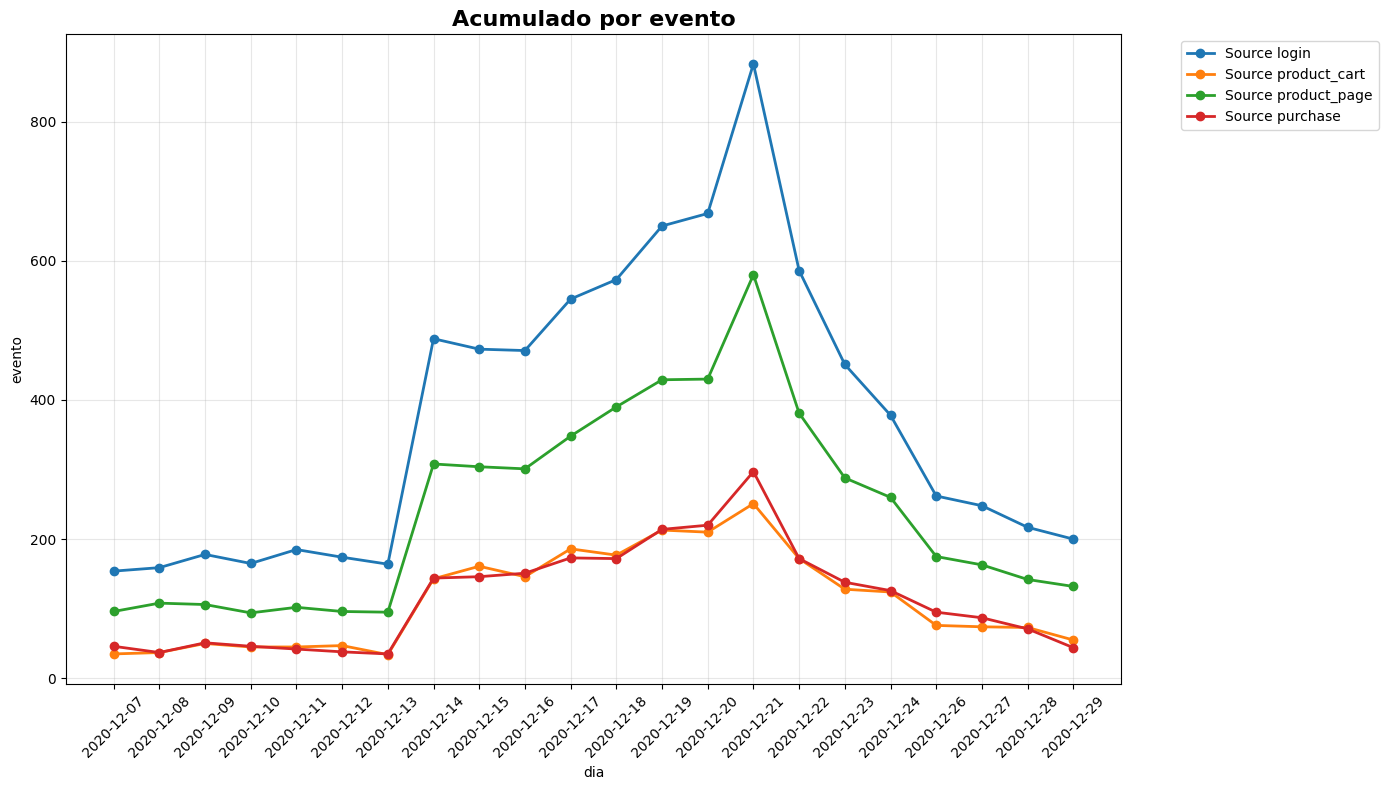

In [78]:
plt.figure(figsize=(14, 8))

for group in events_by_date_a['event_name'].unique():
    data_source = events_by_date_a[events_by_date_a['event_name'] == group]
    plt.plot(data_source['date'].astype(str), data_source['user_id'], 
             marker='o', linewidth=2, markersize=6, label=f'Source {group}')

plt.title('Acumulado por evento', fontsize=16, fontweight='bold')
plt.xlabel('dia')
plt.ylabel('evento')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


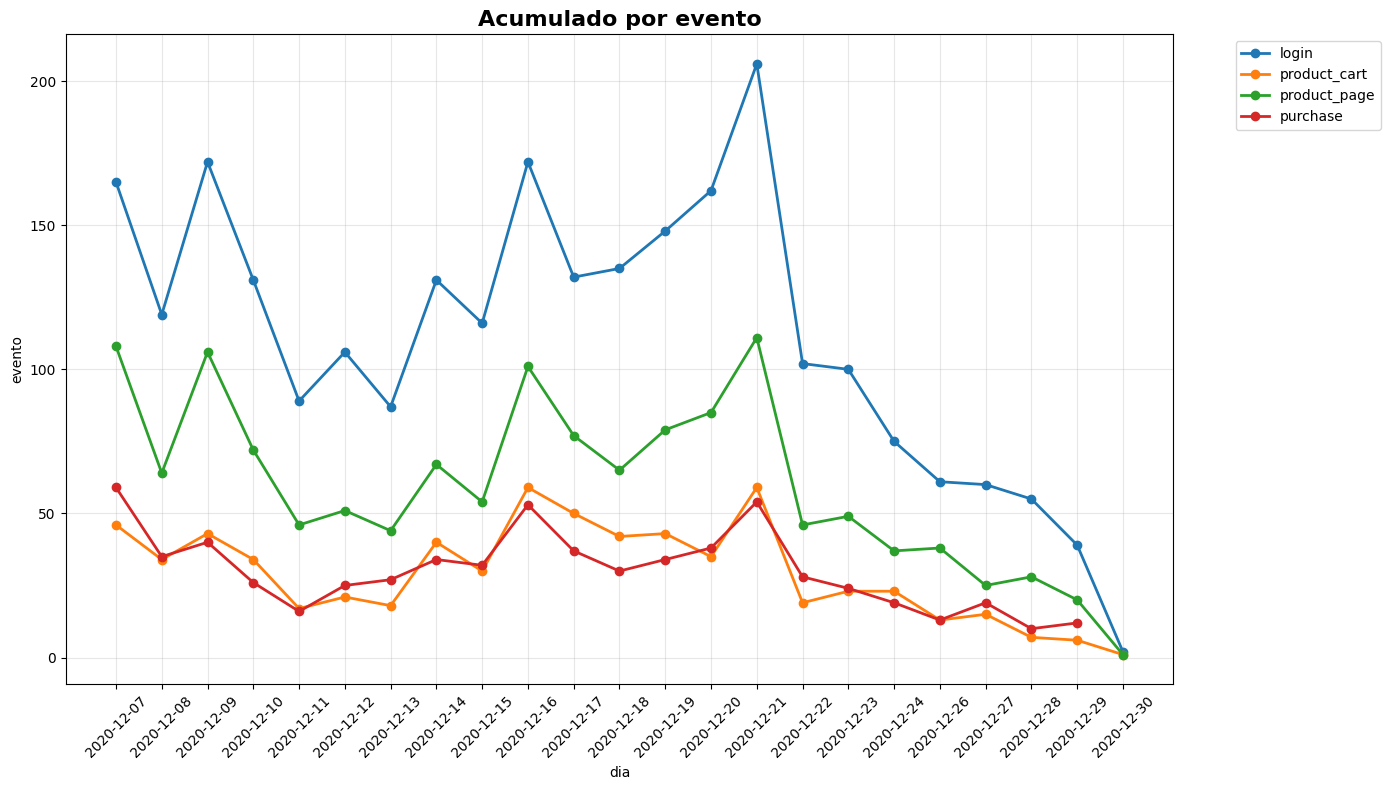

In [79]:
plt.figure(figsize=(14, 8))

for group in events_by_date_b['event_name'].unique():
    data_source = events_by_date_b[events_by_date_b['event_name'] == group]
    plt.plot(data_source['date'].astype(str), data_source['user_id'], 
             marker='o', linewidth=2, markersize=6, label=f'{group}')

plt.title('Acumulado por evento', fontsize=16, fontweight='bold')
plt.xlabel('dia')
plt.ylabel('evento')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

El grupo b tiene diferencia conciderable en los primeros dias de la prueba por cada evento

In [80]:
orden=['login','product_page','product_cart','purchase']

def test_embudo(usuarios_grupo_a, usuarios_grupo_b, pasos_embudo):
    """
    Aplica proportions_ztest para cada paso del embudo
    """
    resultados_test = []
    
    for i, paso in enumerate(pasos_embudo):
       
        if i == 0:
            n1 = usuarios_grupo_a[usuarios_grupo_a['event']==paso]['users'] 
            n2 = usuarios_grupo_b[usuarios_grupo_b['event']==paso]['users'] 
            exitos1 = usuarios_grupo_a[usuarios_grupo_a['event']==paso]['users']  
            exitos2 = usuarios_grupo_b[usuarios_grupo_b['event']==paso]['users']
            n1=float(n1)
            n2=float(n2)
            exitos1=float(exitos1)
            exitos2=float(exitos2)
        else:
            
            n1 = usuarios_grupo_a[usuarios_grupo_a['event']==pasos_embudo[i-1]]['users']   
            n2 = usuarios_grupo_b[usuarios_grupo_b['event']==pasos_embudo[i-1]]['users']  
            exitos1 = usuarios_grupo_a[usuarios_grupo_a['event']==paso]['users']  
            exitos2 = usuarios_grupo_b[usuarios_grupo_b['event']==paso]['users']
            n1=float(n1)
            n2=float(n2)
            exitos1=float(exitos1)
            exitos2=float(exitos2)
        
        # Aplicar test de proporciones solo si hay suficientes datos
        if n1 > 0 and n2 > 0 and i>0:
            
            stat, p_value = proportions_ztest([exitos1, exitos2], [n1, n2], alternative='two-sided')
            
            # Calcular proporciones
            prop_a = (exitos1 / n1) * 100
            prop_b = (exitos2 / n2) * 100
            diferencia = prop_a - prop_b
            
            resultados_test.append({
                'paso': paso,
                'orden_paso': i + 1,
                'grupo_A_usuarios': exitos1,
                'grupo_B_usuarios': exitos2,
                'grupo_A_conversion_%': round(prop_a, 2),
                'grupo_B_conversion_%': round(prop_b, 2),
                'diferencia_%': round(diferencia, 2),
                'p_value': p_value,
                'significativo': p_value < 0.05
            })
        else:
            resultados_test.append({
                'paso': paso,
                'orden_paso': i + 1,
                'grupo_A_usuarios': exitos1,
                'grupo_B_usuarios': exitos2,
                'grupo_A_conversion_%': 0,
                'grupo_B_conversion_%': 0,
                'diferencia_%': 0,
                'p_value': np.nan,
                'significativo': False
            })
    
    return pd.DataFrame(resultados_test)

In [85]:
def calculo_proporcion(df):
    df=df.groupby('event_name')['user_id'].nunique().reset_index()
    
    result = df[df['event_name'].isin(orden)].copy()
    result['order'] = result['event_name'].map({event: i for i, event in enumerate(orden)})
    result = result.sort_values('order')

    funnel_analysis = []
    total_users = result[result['event_name'] == 'login']['user_id'].values[0]

    for i, (event, count) in enumerate(zip(result['event_name'], result['user_id'])):
        if i == 0:
            conversion_rate = 100.0  # Primer paso = 100%
            dropoff_rate = 0.0

            users_lost = 0
        else:
            previous_count = result.iloc[i-1]['user_id']
            conversion_rate = (count / previous_count) * 100
            dropoff_rate = 100 - conversion_rate
            users_lost = previous_count - count
    
        funnel_analysis.append({
            'step': i + 1,
            'event': event,
            'users': count,
            'conversion_rate_%': conversion_rate,
            'dropoff_rate_%': dropoff_rate,
            'users_lost': users_lost,
            'overall_conversion_%': (count / total_users) * 100
            })

    df_analysis = pd.DataFrame(funnel_analysis)
    return df_analysis

In [89]:
analisis_a=calculo_proporcion(grupo_a)
analisis_b=calculo_proporcion(grupo_b)
#frecuencia_a=grupo_a.groupby('event_name')['user_id'].count().reset_index()
#frecuencia_b=grupo_b.groupby('event_name')['user_id'].count().reset_index()
test_a_b=test_embudo(analisis_a,analisis_b,orden)
test_a_b

/.venv/lib/python3.9/site-packages/statsmodels/stats/proportion.py:859: RuntimeWarning: invalid value encountered in sqrt
  std_diff = np.sqrt(var_)


,paso,orden_paso,grupo_A_usuarios,grupo_B_usuarios,grupo_A_conversion_%,grupo_B_conversion_%,diferencia_%,p_value,significativo
0,login,1,2747.0,927.0,0.00,0.00,0.00,NaN,False
1,product_page,2,1780.0,523.0,64.80,56.42,8.38,0.000005,True
2,product_cart,3,824.0,255.0,46.29,48.76,-2.47,0.320620,False
3,purchase,4,872.0,256.0,105.83,100.39,5.43,NaN,False


basado en el analisis no hay diferencia siginificativa enre los grupos a y b por lo que la prueba no fue exitosa